# LIMPEZA DE DADOS E DIVIR OS DADOS DE TREINO/TESTE

Esse notebook basicamente faz a leitura do `RESULTADOS_2025.csv`, aplica os filtros, sorteia 8 000 linhas e separa 80% dos dados para treino e 20% para o teste. A variâvel alvo da regressão é `NU_NOTA_MT`, que é a nota de matemática do estudante no enem.

# 1. Parâmetros
Definição dos parâmetros

In [19]:
import csv
from pathlib import Path

import numpy as np
from machinelearning_mnpkllps.Preprocessing import train_test_split

CSV = Path("../data/RESULTADOS_2025.csv")
PROC = Path("../data")     # onde serão salvos treino.csv e teste.csv
N_SAMPLE = 250000            # linhas da amostra Total de linhas: 4810772
TEST_SIZE = 0.2            # fração do teste
SEED = 20251               # semente do sorteio da amostra e do split

TARGET = "NU_NOTA_MT"
NUMERIC = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3","NU_NOTA_COMP4","NU_NOTA_COMP5"]
CATEGORICAL = ["SG_UF_ESC", "TP_LINGUA"]
FEATURES = NUMERIC + CATEGORICAL

# 2. APLICANDO OS FILTROS E PREPARANDO OS DADOS

Só as colunas acima (e as de presença/status da redação, usadas nos filtros) são lidas. 


Filtros: (1) presente nas 4 provas, (2) redação sem problemas, (3) escola informada (dependência, localização e UF) e língua (espanhol/inglês) informada. A amostra é **uniforme**: fazendo reservoir sampling com semente, que sorteia `N_SAMPLE` linhas.

In [20]:
def num(s):
    return float(s.replace(",", "."))      # aceita decimal com vírgula

rng = np.random.default_rng(SEED)
amostra, vistas = [], 0
funil = {"Total de linhas": 0, "Presente nas 4 provas": 0, "Redação sem problemas": 0, "Lingua informada": 0}

with open(CSV, encoding="latin-1", newline="") as f: #esse csv ta com encoding diferente
    leitor = csv.reader(f, delimiter=";")
    col = {nome.strip(): i for i, nome in enumerate(next(leitor))}
    i_pres = [col[c] for c in ("TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT")]
    i_status = col["TP_STATUS_REDACAO"]
    i_num = [col[c] for c in NUMERIC + [TARGET]]
    i_cat = [col[c] for c in CATEGORICAL]

    for linha in leitor:
        if len(linha) < len(col):                         # ignora linha truncada
            continue
        funil["Total de linhas"] += 1
        if any(linha[j] != "1" for j in i_pres):          # filtro 1  ESTUDANTE QUE SE AUSENTOU EM UMA PROVA
            continue
        funil["Presente nas 4 provas"] += 1
        if linha[i_status] != "1":                        # filtro 2   A REDAÇÃO TEVE ALGUM PROBLEMA
            continue
        funil["Redação sem problemas"] += 1
        uf, lingua = (linha[j].strip() for j in i_cat)
        if "" in (uf, lingua):                          # filtro 3 LÍNGUA INFORMADA
            continue
        funil["Lingua informada"] += 1

        cn, ch, lc, red1, red2, red3, red4, red5, mt = (num(linha[j]) for j in i_num) # PADRONIZANDO DOS DADOS NUMÉRICOS
        registro = [cn, ch, lc, red1, red2, red3, red4, red5, uf, int(num(lingua)), mt]

        # Usa o reservoir sampling onde as N_SAMPLE primeiras entram e depois cada uma substitui uma da amostra
        if vistas < N_SAMPLE:
            amostra.append(registro)
        else:
            j = int(rng.integers(0, vistas + 1))
            if j < N_SAMPLE:
                amostra[j] = registro
        vistas += 1

total = funil["Total de linhas"]
sem_problemas = funil["Lingua informada"]

print(f"\nEstudantes sem problemas em nenhum dos critérios: "
      f"{100 * sem_problemas / total:.2f}%")


Estudantes sem problemas em nenhum dos critérios: 25.05%


## 3. Split treino/teste e arquivos

Split com a função da biblioteca e a mesma semente. A análise exploratória deve olhar apenas `treino.csv`.

In [21]:
dados = np.array(amostra, dtype=object)           # colunas: FEATURES + [TARGET]
X, y = dados[:, :-1], dados[:, -1].astype(float) #DIVIDINDO, A ÚLTIMA COLUNA É O ALVO
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, seed=SEED)

def salvar(X, y, nome):
    with open(PROC / nome, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(FEATURES + [TARGET]) #concatenação de listas
        w.writerows(np.column_stack([X, y]).tolist()) #concatena as colunas e dpoies trandforma em lista

salvar(Xtr, ytr, "treino.csv")
salvar(Xte, yte, "teste.csv")
print(f"treino = {len(ytr):,}  teste = {len(yte):,}  salvos em {PROC}".replace(",", "."))

treino = 200.000  teste = 50.000  salvos em ..\data


# Modelagem (regressão: `NU_NOTA_MT`, ENEM 2025)

Pipeline com a biblioteca `machinelearning-mnpkllps`:

1. **Dados** → 2. **Pré-processamento** → 3. **Modelos** → 4. **Validação cruzada** → 5. **Avaliação final no teste** → 6. **Interpretação**

Entrada: `data/treino.csv` e `data/teste.csv` (gerados pelo notebook `preparar_dados.ipynb`). O teste só é usado na etapa 5. A análise exploratória está no notebook `analise_exploratoria.ipynb`.

In [22]:
from importlib.metadata import version # version(package) returns the installed version of a package, so the output records which library version produced the results

import numpy as np

from machinelearning_mnpkllps import Metrics
from machinelearning_mnpkllps.NeuralNetwork import NeuralNetwork
from machinelearning_mnpkllps.Regression import MinimosQuadrados, RegressaoPolinomial, Ridge, Lasso
from machinelearning_mnpkllps.Resampling import KFold
from machinelearning_mnpkllps.Preprocessing import StandardScaler

SEED = 20251

# Hyperparameters
K = 5          # number of folds
# degrees of the polynomial for polynomial regression (with NU_NOTA_CN as the only predictor)
D_1 =  2      
D_2 = 4
D_3 = 8
# Lasso constants (alpha is on the scale of the score points, so it needs values of this size to change the coefficients)
C_1 = 0.1
C_2 = 1
C_3 = 3
C_4 = 10
C_5 = 30
C_6 = 60
# Ridge constants: the Lasso ones divided by 10, since for the same alpha the Ridge penalty (n * alpha in the library) shrinks the coefficients much more
R_1, R_2, R_3, R_4, R_5, R_6 = C_1 / 10, C_2 / 10, C_3 / 10, C_4 / 10, C_5 / 10, C_6 / 10 # tuple unpacking: each name on the left gets the value in the same position on the right
# Neural network
LAYERS = ((16,), (32, 16)) # hidden layers of each architecture tested: (16,) is one hidden layer with 16 neurons, (32, 16) two hidden layers
LEARNING_RATES = (0.01, 0.05)
EPOCHS = 50
BATCH = 64 # number of samples in each gradient descent step
print("library version:", version("machinelearning-mnpkllps"))

library version: 0.2.86


## 1. Dados

Só a leitura do treino e do teste. A análise exploratória foi feita no notebook `analise_exploratoria.ipynb`.

In [23]:
Target = "NU_NOTA_MT"
Numeric = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"] # scores of the other exams and of the 5 essay competences (the essay total is left out, since it is the sum of the 5 competences)
Categorical = ["SG_UF_ESC", "TP_LINGUA"] # school state and foreign language

def _read(path):
	# np.genfromtxt reads a CSV into a numpy structured array. names=True takes the column names from the header, so a column can be accessed as data["COLUMN_NAME"]; dtype=None lets numpy infer the type of each column (number or text)
	return np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8")

train, test = _read("../data/treino.csv"), _read("../data/teste.csv")
ytr, yte = train[Target].astype(float), test[Target].astype(float) # astype(float) converts the column into a float array
print(f"train = {len(ytr)} rows, test = {len(yte)} rows")

train = 200000 rows, test = 50000 rows


## 2. Pré-processamento

* **Notas** (numéricas): padronizadas com o `StandardScaler` da biblioteca **dentro do `fit` de cada modelo** (`with_scaling`, na etapa 3). Na validação cruzada, a média e o desvio vêm só das dobras de treino, então a dobra de validação não vaza para a padronização; na avaliação final, vêm de todo o treino.
* **Categóricas**: viram colunas 0/1 (dummies). A categoria mais frequente do treino é a referência e não ganha coluna; uma categoria inédita no teste cai na referência.

In [24]:
# The dummies are built by hand instead of using ColumnCategoricalEncoder from our preprocessing module because:
# 1. With drop_first=True, our encoder drops the first category in sorted order (np.unique sorts them), e.g. "AC" for the states.
# Here we want the most frequent category of the training set as the baseline, so each dummy coefficient compares a category with the most common case.
# 2. Our encoder raises ValueError when the test set has a category that was not seen in fit. With 27 states and some rare categories,
# a category may appear only in the test set. Here such a row simply gets 0 in all its dummies, i.e., it falls into the baseline category.
# The logic is the same one used inside CategoricalEncoder.transform (comparing a column vector with a row vector), only with these two changes.

def get_column(sample, c):
	col = sample[c]
	# dtype.kind is a one-letter code of the array type: 'f' float, 'i' integer, 'U' text. Code columns (e.g. TP_LINGUA = 0 or 1) may be read as float, so they become int to give clean category names (1 instead of 1.0)
	return col.astype(int) if col.dtype.kind == "f" else col

# categories of each variable, from the most to the least frequent; the first one (baseline) is dropped
categories = {}
for c in Categorical:
	values, counts = np.unique(get_column(train, c), return_counts=True) # np.unique returns the sorted distinct values and, with return_counts=True, how many times each one appears. Two distinct 1D arrays of the same length are returned: values[i] appears counts[i] times in the column
	categories[c] = values[np.argsort(-counts)][1:] # np.argsort(-counts) gives the indices that sort counts in decreasing order (sorting -counts ascending = sorting counts descending); [1:] drops the most frequent category, the baseline, starting from index 1

# names of the columns of the design matrix, used later to interpret the Ridge coefficients
feature_names = Numeric + [f"{c}={v}" for c in Categorical for v in categories[c]] # f"{c}={v}" is a formatted string, e.g. "TP_LINGUA=1", the dummy of Spanish (1) when English (0) is the baseline

def build_design_matrix(sample):
	"""Returns the design matrix of a sample: the scores (not standardized yet) followed by the dummy columns"""
	# np.column_stack joins the score columns side by side into a (n_samples, len(Numeric)) matrix.
	# The scores are standardized later, inside the fit of each model (see with_scaling), so that the mean and std only come from the data the model is trained on
	scores = np.column_stack([sample[c] for c in Numeric]).astype(float)
	# Indexing with None adds a new axis: column[:, None] has shape (n, 1) and categories[c][None, :] has shape (1, K-1).
	# Comparing them with == gives a (n, K-1) boolean matrix, True where the row has that category. The baseline or a category not seen in training gives a row of all False. Same logic as CategoricalEncoder.transform, but with the two changes explained above.
	dummies = np.column_stack([get_column(sample, c)[:, None] == categories[c][None, :] for c in Categorical])
	return np.column_stack([scores, dummies.astype(float)]) # astype(float) turns True/False into 1/0

X_train, X_test = build_design_matrix(train), build_design_matrix(test)
print("design matrix:", X_train.shape, "(train),", X_test.shape, "(test)")

design matrix: (200000, 35) (train), (50000, 35) (test)


## 3. Modelos

Comparamos seis modelos: **baseline** (prevê a média), **Mínimos Quadrados**, **regressão polinomial**, **Ridge**, **Lasso** e **rede neural**. Os hiperparâmetros testados estão no início do notebook. O `KFold` da biblioteca pede uma classe com `fit` e `predict`; o baseline e a rede precisam de uma classe pequena para isso. Na rede, `y` é padronizado para o treino e a previsão volta para a escala de pontos. Os modelos que usam as notas passam por `with_scaling`, que faz a padronização dentro do `fit`.

A regressão polinomial usa a `RegressaoPolinomial` da biblioteca, que aceita uma única variável explicativa: por isso ela usa só `NU_NOTA_CN`, a nota mais correlacionada com a de matemática.

In [25]:
class MeanBaseline:
	"""Always predicts the mean of y in the training data. Any useful model must do better than this."""
	def __init__(self, hip=None): pass # KFold may create the class with a hyperparameter; the baseline has none, so it is ignored
	def fit(self, X, y): self.m = y.mean(); return self
	def predict(self, X): return np.full(len(X), self.m) # np.full(n, value) creates an array of size n filled with value


def make_network(hidden_layers, lr, epochs):
	"""Wraps the library's neural network into a class with fit/predict, as KFold requires (the network expects X with one sample per column)"""
	# KFold receives a class and creates a new object for each fold, so we cannot give it an already configured object.
	# This function builds and returns a new class that remembers hidden_layers, lr and epochs (a closure), so each configuration of the grid becomes its own class
	class Network:
		def __init__(self, hip=None): pass

		def fit(self, X, y):
			# y is standardized for training: with tanh and small initial weights, the network learns much better with targets around 0 than with scores around 500
			self.m, self.s = y.mean(), y.std()
			# [X.shape[1], *hidden_layers, 1]: an input layer with one neuron per feature, the hidden layers (* unpacks the tuple into the list) and one output neuron
			self.net = NeuralNetwork([X.shape[1], *hidden_layers, 1], "tanh", "identity",
					bias_interval=(-0.1, 0.1), weight_interval=(-0.1, 0.1), seed=SEED)
			# X.T transposes X to (n_features, n_samples) and reshape(1, -1) turns y into a (1, n_samples) row, the format the network expects
			self.net.fit(X, ((y - self.m) / self.s).reshape(-1, 1), learn_rate=lr, batch=BATCH, epochs=epochs)
			return self

		# prevision returns a (1, n_samples) matrix; ravel() flattens it into a 1D vector, and * s + m undoes the standardization, going back to points
		def predict(self, X):
    			return self.net.prevision(X).ravel() * self.s + self.m

	return Network


def with_scaling(model_class):
	"""Returns a version of model_class that standardizes the score columns inside fit, using only the data it is trained on"""
	# Inside KFold, fit only receives the training folds, so the mean and std never see the validation fold (no data leakage).
	# In the final evaluation, fit receives the whole training set, so the test set is transformed with the training mean and std.
	n_scores = len(Numeric) # the scores are the first columns of the design matrix; the other columns are the 0/1 dummies, which are not standardized
	class Scaled:
		def __init__(self, hip=None):
			self.model = model_class(hip) if hip is not None else model_class() # the original model, created with or without its hyperparameter

		def _scale(self, X):
			X = X.copy() # copy, so that the matrix given by KFold is not modified
			X[:, :n_scores] = self.scaler.transform(X[:, :n_scores]) # X[:, :n_scores] selects all the rows and the first n_scores columns
			return X

		def fit(self, X, y):
			self.scaler = StandardScaler().fit(X[:, :n_scores]) # mean and std of the data given to fit only
			self.model.fit(self._scale(X), y)
			return self

		def predict(self, X):
			return self.model.predict(self._scale(X)) # new data is transformed with the mean and std learned in fit
	return Scaled

## 4. Validação cruzada (só no treino)

K-fold com K = 5 e a mesma semente para todos, então todas as configurações são avaliadas nas mesmas dobras. Em cada modelo, fica a configuração com menor RMSE. O teste não participa da escolha.

Esse RMSE não é um erro de treino, é o erro na dobra de validação: em cada dobra, o modelo é ajustado em 4 dobras e o erro é medido na 5ª (validação), que ele não viu. Por isso escolher o menor CV-RMSE é o método padrão para escolher hiperparâmetros. Se o menor erro ficar no menor alpha, a conclusão é que, com 6 400 observações, a regularização quase não ajuda a prever, e não que o método falhou.

In [26]:
# For each model family, a list of (class, hyperparameter, description).
# with_scaling(...) is only skipped for the baseline, which does not use X
grids = {
	"Baseline":         [(MeanBaseline, None, "mean")],
	"MinimosQuadrados": [(with_scaling(MinimosQuadrados), None, "-")],
	"Polynomial":       [(with_scaling(RegressaoPolinomial), d, f"degree={d}") for d in (D_1, D_2, D_3)],
	"Ridge":            [(with_scaling(Ridge), a, f"alpha={a}") for a in (R_1, R_2, R_3, R_4, R_5, R_6)],
	"Lasso":            [(with_scaling(Lasso), a, f"alpha={a}") for a in (C_1, C_2, C_3, C_4, C_5, C_6)],
	"NeuralNetwork":    [(with_scaling(make_network(h, lr, EPOCHS)), None, f"layers={h}, lr={lr}")
						for h in LAYERS for lr in LEARNING_RATES],
}

# Training and test matrices of each family. The library's RegressaoPolinomial only accepts one feature,
# so the polynomial regression receives only the NU_NOTA_CN column; the other families receive the whole design matrix
cn = Numeric.index("NU_NOTA_CN") # position of the NU_NOTA_CN column in the design matrix
data = {family: (X_train, X_test) for family in grids} # dictionary comprehension: one (train, test) pair for each family
data["Polynomial"] = (X_train[:, [cn]], X_test[:, [cn]]) # [cn] (a list) keeps the column as a (n, 1) matrix, while cn alone would give a 1D vector.
# with_scaling still works here: X[:, :n_scores] of a matrix with a single column is that column, so only NU_NOTA_CN is standardized

best = {}
for family, options in grids.items(): # .items() goes through the (key, value) pairs of the dictionary
	results = []
	
	for cls, hip, description in options:
		# KFold(...).folds() returns the mean MSE over the K folds; the square root turns it into RMSE, in points like the score.
		# The same seed gives the same folds for every configuration, so all of them are compared on the same data
		rmse = np.sqrt(KFold(cls, data[family][0], ytr, k=K, hip=hip, seed=SEED).folds())

		results.append((rmse, cls, hip, description))
		print(f"{family:17s} {description:26s} CV-RMSE = {rmse:.2f}") # :17s pads the text to 17 characters, to align the columns
	best[family] = min(results, key=lambda r: r[0]) # key=lambda r: r[0] makes min compare the tuples only by their first element, the RMSE

Baseline          mean                       CV-RMSE = 125.59
MinimosQuadrados  -                          CV-RMSE = 79.28
Polynomial        degree=2                   CV-RMSE = 88.98
Polynomial        degree=4                   CV-RMSE = 88.40
Polynomial        degree=8                   CV-RMSE = 88.26
Ridge             alpha=0.01                 CV-RMSE = 79.42
Ridge             alpha=0.1                  CV-RMSE = 79.78
Ridge             alpha=0.3                  CV-RMSE = 80.49
Ridge             alpha=1.0                  CV-RMSE = 83.62
Ridge             alpha=3.0                  CV-RMSE = 91.50
Ridge             alpha=6.0                  CV-RMSE = 99.35
Lasso             alpha=0.1                  CV-RMSE = 79.45
Lasso             alpha=1                    CV-RMSE = 79.85
Lasso             alpha=3                    CV-RMSE = 80.10
Lasso             alpha=10                   CV-RMSE = 81.17
Lasso             alpha=30                   CV-RMSE = 88.33
Lasso             alpha

## 5. Avaliação final no teste

Cada modelo escolhido é reajustado em todo o treino e avaliado no teste.

In [27]:
models = {}
for family, (rmse_cv, cls, hip, description) in best.items():
	# refits the chosen configuration on the whole training set; fit returns self, so it can be chained right after creating the object
	model = (cls(hip) if hip is not None else cls()).fit(data[family][0], ytr)
	models[family] = model
	p = model.predict(data[family][1])
	# :6.2f writes the number with 2 decimals in a field of 6 characters; two f-strings next to each other are joined into a single string
	print(f"{family:17s} CV-RMSE={rmse_cv:6.2f} | test: RMSE={Metrics.RMSE(p, yte):6.2f}"
      f"  MAE={Metrics.MAE(p, yte):6.2f}  R2={Metrics.R2(p, yte):.3f}")

Baseline          CV-RMSE=125.59 | test: RMSE=126.15  MAE=104.30  R2=-0.000
MinimosQuadrados  CV-RMSE= 79.28 | test: RMSE= 78.90  MAE= 63.02  R2=0.609
Polynomial        CV-RMSE= 88.26 | test: RMSE= 88.17  MAE= 70.84  R2=0.511
Ridge             CV-RMSE= 79.42 | test: RMSE= 79.00  MAE= 63.12  R2=0.608
Lasso             CV-RMSE= 79.45 | test: RMSE= 79.02  MAE= 63.13  R2=0.608
NeuralNetwork     CV-RMSE= 75.57 | test: RMSE= 75.26  MAE= 59.81  R2=0.644


## 6. Análise dos resultados

In [28]:
import matplotlib.pyplot as plt

# predictions on the test set of the model chosen in each family (the same refitted models of section 5)
preds = {f: models[f].predict(data[f][1]) for f in models}
cv_rmse = {f: best[f][0] for f in best}                       # CV-RMSE of the chosen configuration
test_rmse = {f: Metrics.RMSE(preds[f], yte) for f in preds}   # RMSE on the test set

# best model = lowest CV-RMSE, baseline excluded (the choice does not use the test set)
best_family = min((f for f in best if f != "Baseline"), key=lambda f: cv_rmse[f])
print("Melhor modelo pelo CV-RMSE (sem contar o baseline):", best_family)

Melhor modelo pelo CV-RMSE (sem contar o baseline): NeuralNetwork


### 6.1 Comparação dos modelos

Para cada modelo, o gráfico compara o RMSE da validação cruzada com o RMSE no teste. Barras menores = erro menor.

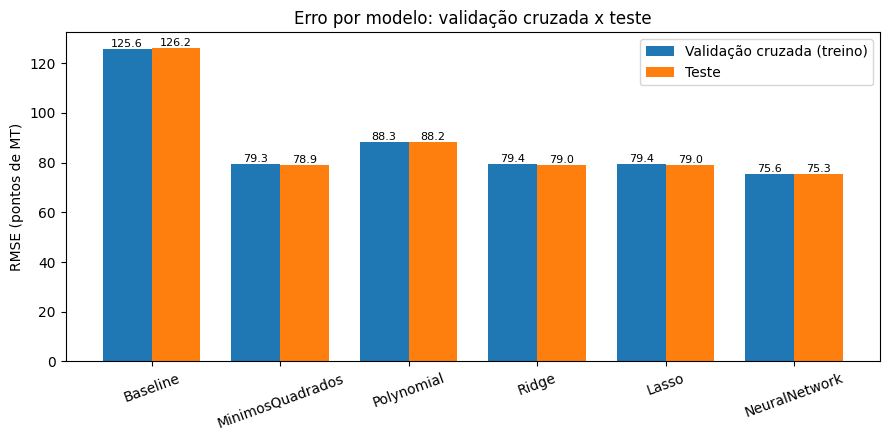

In [29]:
families = list(models)
x_pos = np.arange(len(families))
bar_w = 0.38

fig, ax = plt.subplots(figsize=(9, 4.5))
bars_cv = ax.bar(x_pos - bar_w / 2, [cv_rmse[f] for f in families], bar_w, label="Validação cruzada (treino)")
bars_te = ax.bar(x_pos + bar_w / 2, [test_rmse[f] for f in families], bar_w, label="Teste")
ax.bar_label(bars_cv, fmt="%.1f", fontsize=8)
ax.bar_label(bars_te, fmt="%.1f", fontsize=8)
ax.set_xticks(x_pos, families, rotation=20)
ax.set_ylabel("RMSE (pontos de MT)")
ax.set_title("Erro por modelo: validação cruzada x teste")
ax.legend()
plt.tight_layout()
plt.show()

Os resultados mostram resultados semelhante para todos os modelos (exceto baseline que serve para comparação), com destaque ao regressão polinomial que foi um pouco pior e a rede neural que apresentou um melhor desempenho.


### 6.2 Quais variáveis mais pesam (Ridge)

Os coeficientes do Ridge (seção 6) em gráfico. Nas notas, o coeficiente é a variação em pontos de MT para 1 desvio-padrão da nota, mantidas as outras variáveis; nas dummies, é a diferença em pontos em relação à categoria de referência (a mais frequente no treino, impressa abaixo do gráfico). Azul = associação positiva, vermelho = negativa.

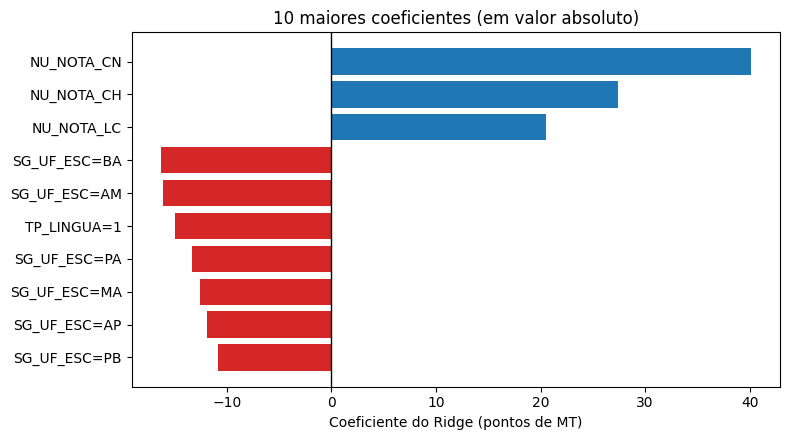

Referência de SG_UF_ESC: SP
Referência de TP_LINGUA: 0

Coeficientes das notas (por 1 desvio-padrão):
  NU_NOTA_CN        40.07
  NU_NOTA_CH        27.42
  NU_NOTA_LC        20.54
  NU_NOTA_COMP1      3.94
  NU_NOTA_COMP2      1.60
  NU_NOTA_COMP3      2.85
  NU_NOTA_COMP4     10.24
  NU_NOTA_COMP5      5.98

Alunos no treino dos estados entre os 10 maiores coeficientes:
  BA: 14799
  AM: 4131
  PA: 8604
  MA: 7358
  AP: 1055
  PB: 4699


In [30]:
ridge_coef = models["Ridge"].model.coeficientes[1:]       # [0] is the intercept
top = np.argsort(-np.abs(ridge_coef))[:10][::-1]          # 10 largest in absolute value; reversed so the largest is drawn on top

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([feature_names[i] for i in top], ridge_coef[top],
        color=["tab:blue" if ridge_coef[i] > 0 else "tab:red" for i in top])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Coeficiente do Ridge (pontos de MT)")
ax.set_title("10 maiores coeficientes (em valor absoluto)")
plt.tight_layout()
plt.show()

# reference category of each variable (the most frequent in the training set)
for c in Categorical:
    values, counts = np.unique(get_column(train, c), return_counts=True)
    print(f"Referência de {c}: {values[np.argmax(counts)]}")

print("\nCoeficientes das notas (por 1 desvio-padrão):")
for name, c in zip(Numeric, ridge_coef[:len(Numeric)]):
    print(f"  {name:15s} {c:7.2f}")

# how many training students each state among the top-10 coefficients has
uf_col = get_column(train, "SG_UF_ESC")
print("\nAlunos no treino dos estados entre os 10 maiores coeficientes:")
for i in top[::-1]:
    if feature_names[i].startswith("SG_UF_ESC="):
        uf = feature_names[i].split("=")[1]
        print(f"  {uf}: {int(np.sum(uf_col == uf))}")

**Interpretação dos coeficientes**

* **As notas das outras provas dominam.** `NU_NOTA_CN`, `NU_NOTA_CH` e `NU_NOTA_LC` são os maiores coeficientes.
* **A UF da escola pesa de forma moderada.** Os maiores coeficientes de estado (BA,AM,PA,MA,AP,PB) indicam notas médias menores que as do estado de referência, com as demais variáveis fixas.
* **A língua estrangeira:** `TP_LINGUA=1` (espanhol) indica, em relação à língua de referência, uma nota média menor para quem escolheu a outra língua (inglês).

## 7. Conclusão

- Todos os modelos superam bem o baseline.
- Os modelos lineares praticamente empatam.
- A rede neural é a melhor
- O que mais explica a nota de matemática são as notas das outras provas

**Limites**

* Só entram participantes presentes nas 4 provas, com redação sem problemas e com a UF da escola e a língua informadas: o recorte não representa todos os participantes.
* A base não tem renda, raça ou sexo; os coeficientes não indicam causalidade.